# Week 2: Mechanics and Data Quality
Verify that you can trust the data you downloaded.

In [1]:
# Load your data from ../data/ (see the setup notebook)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKERS = ["SPY", "RSP"]    # <- change to your pair (exact Yahoo Finance tickers)
SPY_prices = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
RSP_prices = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)
SPY_prices.tail() #view last 5 rows as an example

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,685.029480,690.380005,690.830017,687.799988,687.950012,39445600
2025-12-26,684.960022,690.309998,691.659973,689.270020,690.640015,41613300
2025-12-29,682.519043,687.849976,689.200012,686.070007,687.539978,62559500
2025-12-30,681.685608,687.010010,688.559998,686.580017,687.450012,47160700
2025-12-31,676.635010,681.919983,687.359985,681.710022,687.140015,74144800


## Visual
Plot three versions of the price for each asset on one chart:

1. **Raw Close**: the price that actually traded that day
2. **Close**: adjusted for splits only
3. **Adj Close**: adjusted for splits and dividends

Yahoo doesn't give you the raw price, because its `Close` is already split-adjusted.
To rebuild it, multiply every price *before* a split by that split's ratio (take the time to learn this code):

    splits = yf.Ticker("TICKER").splits
    splits.index = splits.index.tz_localize(None)
    factor = pd.Series(1.0, index=df.index)
    for date, ratio in splits.items():
        factor[df.index < date] *= ratio
    df["Raw Close"] = df["Close"] * factor

Use `logy=True` when plotting so the lines are readable.

**What to look for:**
- **Splits**: Raw Close drops suddenly while Close and Adj Close don't. If your asset has never split, Raw Close sits exactly on top of Close.
- **Dividends**: Close and Adj Close slowly drift apart. To see this clearly, also plot `df["Adj Close"] / df["Close"]`. It steps up each time a dividend is paid and stays flat at 1.0 for non-payers.

Check what you find against `yf.Ticker("TICKER").actions`, which lists every split and dividend.

/Users/caiburin/Documents/GitHub/OQG_education_proj/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/caiburin/Documents/GitHub/OQG_education_proj/.venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/caiburin/Documents/GitHub/OQG_education_proj/.venv/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata

SPY splits:
Series([], Name: Stock Splits, dtype: object)
RSP splits:
Date
2006-04-27 09:30:00    4.0
Name: Stock Splits, dtype: float64


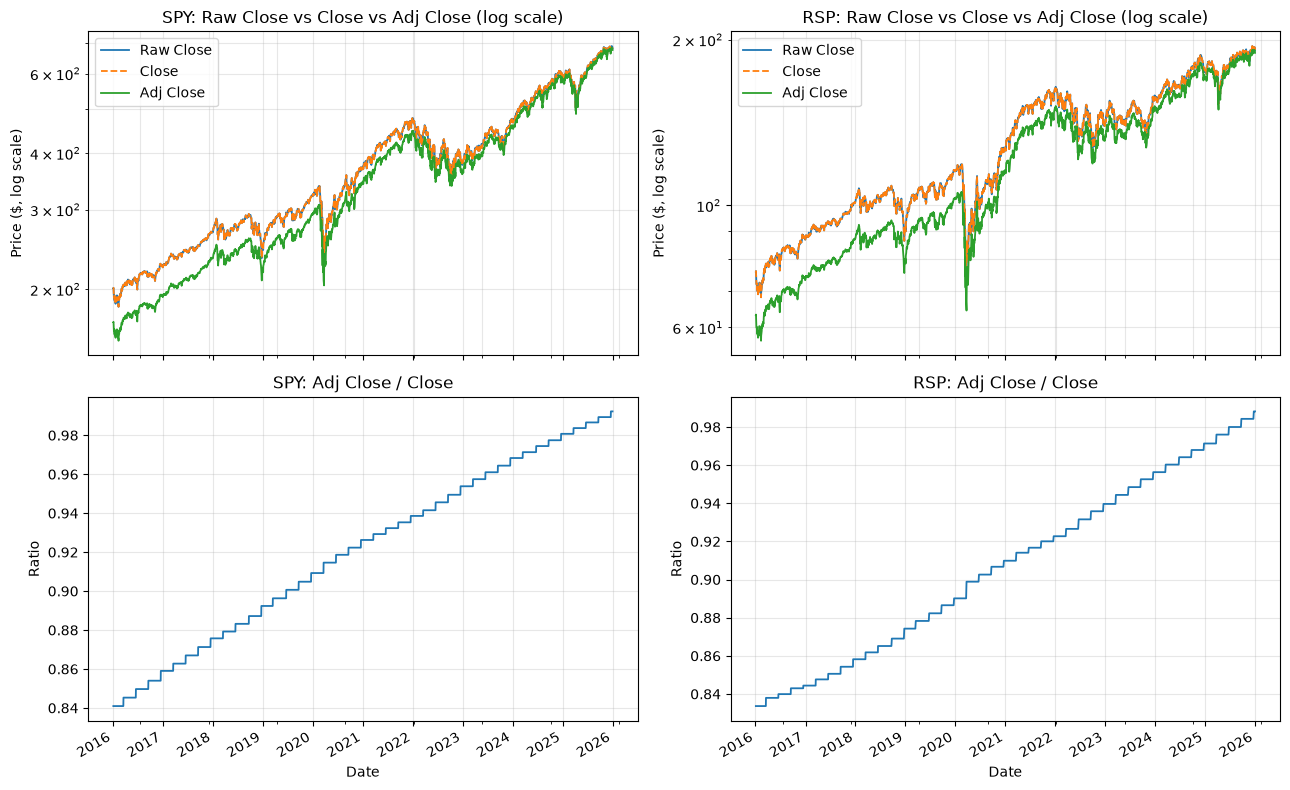

In [2]:
def build_three(ticker, prices):
    """Return a DataFrame with Raw Close, Close and Adj Close for one asset."""
    df = prices.sort_index().copy()                 # oldest to newest; copy so the original isn't changed
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)       # drop timezone so dates compare with the split dates

    splits = yf.Ticker(ticker).splits               # Series of split dates -> split ratios
    splits.index = splits.index.tz_localize(None)   # same timezone fix for the split dates
    print(f"{ticker} splits:\n{splits}")            # empty output means the asset never split

    factor = pd.Series(1.0, index=df.index)         # start with "no adjustment" (1.0) for every day
    for date, ratio in splits.items():
        factor.loc[df.index < date] *= ratio        # days before a split get multiplied by its ratio

    df["Raw Close"] = df["Close"] * factor          # undo Yahoo's split adjustment = price actually traded
    return df[["Raw Close", "Close", "Adj Close"]]  # keep only the three prices to plot

# Build the three-price table for each asset
data = {
    "SPY": build_three("SPY", SPY_prices),
    "RSP": build_three("RSP", RSP_prices),
}

# Two rows x two columns: top = prices, bottom = dividend ratio; one column per asset
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for i, tk in enumerate(["SPY", "RSP"]):
    df = data[tk]

    # Top row: all three prices on a log y-axis; Close is dashed so it stays visible over Raw Close
    df.plot(ax=axes[0, i], logy=True, linewidth=1.3, style=["-", "--", "-"])
    axes[0, i].set_title(f"{tk}: Raw Close vs Close vs Adj Close (log scale)")
    axes[0, i].set_ylabel("Price ($, log scale)")
    axes[0, i].grid(True, which="both", alpha=0.3)

    # Bottom row: Adj Close / Close steps up with each dividend (flat at 1.0 if none are paid)
    (df["Adj Close"] / df["Close"]).plot(ax=axes[1, i], linewidth=1.3)
    axes[1, i].set_title(f"{tk}: Adj Close / Close")
    axes[1, i].set_ylabel("Ratio")
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()   # stop titles and labels from overlapping
plt.show()

## Table
Calculate the **median daily dollar volume** (Close × Volume). Which asset is more liquid?

In [3]:
# Step 1: Daily dollar volume for each asset
# Dollar volume = Close price x number of shares traded that day.
# It measures how much money changed hands, so assets with
# different share prices can be compared fairly.
dollar_vol = pd.DataFrame({
    # Each line multiplies two columns row by row (day by day),
    # so the result is one dollar volume value per trading day.
    # We use "Close" (the price actually paid), not "Adj Close",
    # which is rescaled for later dividends and would understate old days.
    "SPY": SPY_prices["Close"] * SPY_prices["Volume"],
    "RSP": RSP_prices["Close"] * RSP_prices["Volume"],
}).dropna()   # pandas aligns the two series by date; dropna() keeps only dates
              # where both assets have data, so the comparison uses the same days

# Step 2: Summary table
# The median is the middle value, so a few extreme days (such as
# March 2020) don't distort it. The mean is included for comparison:
# if the mean is much larger than the median, a few very busy days
# are pulling it up.
liquidity = pd.DataFrame({
    "Median daily $ volume": dollar_vol.median(),   # typical day, one value per asset
    "Mean daily $ volume":   dollar_vol.mean(),     # average day, one value per asset
})

# Step 3: Display
# Divide by 1e9 (one billion) so the values show in billions of dollars,
# round to 2 decimals, and add "($B)" to each column name.
print((liquidity / 1e9).round(2).rename(columns=lambda c: c + " ($B)"))

# Ratio of the two medians: a value of 40 would mean SPY trades
# about 40 times more dollars on a typical day than RSP does.
print("SPY / RSP (median):", round(dollar_vol["SPY"].median() / dollar_vol["RSP"].median(), 1))
print("SPY is the more liquid asset on a typical day as its medidian daily dollar volume is higher, \n meaning it moves more money on a typical day than RSP. ")

     Median daily $ volume ($B)  Mean daily $ volume ($B)
SPY                       26.57                     29.64
RSP                        0.23                      0.53
SPY / RSP (median): 114.4
SPY is the more liquid asset on a typical day as its medidian daily dollar volume is higher, 
 meaning it moves more money on a typical day than RSP. 


## Defect checks
Look for missing days, zero-volume days, impossible prices and ticker changes. Then fix what you find in code.

In [4]:
#Check for defects
def check_defects(name, df, other_index=None):
    """Print a defect report for one asset and return a dict of flagged dates."""
    flags = {}
    df = df.sort_index()

    # ---------- 1. Missing days ----------
    # Business days (Mon-Fri) between first and last date that are not in the data
    all_bdays = pd.bdate_range(df.index.min(), df.index.max())
    missing = all_bdays.difference(df.index)
    flags["missing_bdays"] = missing

    # Missing in this asset but present in the other = a real data gap.
    # Missing in both = most likely a market holiday, not a defect.
    if other_index is not None:
        flags["gap_not_holiday"] = missing.intersection(other_index)
    # Long gaps between consecutive rows (more than 4 calendar days) also deserve a look
    gaps = df.index.to_series().diff().dt.days
    flags["long_gaps"] = gaps[gaps > 4]

    # NaN values in any column
    flags["nan_rows"] = df.index[df.isna().any(axis=1)]

    # ---------- 2. Zero-volume days ----------
    flags["zero_volume"] = df.index[df["Volume"] <= 0]

    # ---------- 3. Impossible prices ----------
    price_cols = ["Open", "High", "Low", "Close", "Adj Close"]
    bad = (df[price_cols] <= 0).any(axis=1)                      # zero or negative price
    bad |= df["High"] < df["Low"]                                # high below low
    bad |= (df["Close"] > df["High"] * 1.0001) | (df["Close"] < df["Low"] * 0.9999)   # close outside the day's range
    bad |= (df["Open"]  > df["High"] * 1.0001) | (df["Open"]  < df["Low"] * 0.9999)   # open outside the day's range
    flags["impossible_price"] = df.index[bad]

    # Adj Close should never exceed Close, and Adj/Close should not fall over time
    # (it climbs toward 1.0 as dividends are paid). A drop means a bad adjustment.
    ratio = df["Adj Close"] / df["Close"]
    flags["adj_above_close"] = df.index[ratio > 1.0001]
    flags["ratio_drops"] = df.index[ratio.diff() < -0.001]

    # Extreme daily moves: either real (March 2020) or a data error
    ret = df["Adj Close"].pct_change()
    flags["big_moves_>15%"] = ret.index[ret.abs() > 0.15]

    # ---------- 4. Ticker changes / splice points ----------
    # A new ticker or a stitched series often shows up as a one-day price jump
    # that reverses, or an abrupt change in typical volume.
    flags["price_jump_>25%"] = ret.index[ret.abs() > 0.25]
    vol_by_year = df["Volume"].groupby(df.index.year).median()
    flags["volume_by_year"] = vol_by_year

    # ---------- Print the report ----------
    print(f"\n===== {name}: {len(df)} rows, {df.index.min().date()} to {df.index.max().date()} =====")
    for key, val in flags.items():
        if key == "volume_by_year":
            print("Median volume by year:\n", val.astype(int).to_string())
        elif len(val) == 0:
            print(f"{key}: none")
        else:
            print(f"{key}: {len(val)} -> {[str(d.date()) if hasattr(d, 'date') else d for d in val][:15]}")
    return flags


# Clean the data according to the defeect report
def clean_prices(name, df):
    """Return a cleaned copy of the price table and print what was changed."""
    df = df.sort_index().copy()
    n0 = len(df)

    # Duplicate dates: keep the last row for each date
    dups = df.index.duplicated(keep="last")
    df = df[~dups] if False else df[~df.index.duplicated(keep="last")]

    # Impossible prices (zero/negative, High < Low): blank them out, then drop the rows.
    # We drop rather than forward-fill so that no fake 0% return day is created.
    price_cols = ["Open", "High", "Low", "Close", "Adj Close"]
    bad = (df[price_cols] <= 0).any(axis=1) | (df["High"] < df["Low"])
    df.loc[bad, price_cols] = np.nan

    # Rows with missing prices cannot produce a valid return, so drop them
    df = df.dropna(subset=["Adj Close", "Close"])

    # Zero-volume days: keep the row (the price is valid), but mark it so that
    # liquidity statistics can exclude it
    df["Zero volume"] = df["Volume"] <= 0

    print(f"{name}: dropped {n0 - len(df)} rows, flagged {int(df['Zero volume'].sum())} zero-volume days")
    return df

flags_spy = check_defects("SPY", SPY_prices, other_index=RSP_prices.index)
flags_rsp = check_defects("RSP", RSP_prices, other_index=SPY_prices.index)
SPY_clean = clean_prices("\nSPY", SPY_prices)
RSP_clean = clean_prices("RSP", RSP_prices)

# For liquidity, use only days with real trading
spy_dv = (SPY_clean["Close"] * SPY_clean["Volume"])[~SPY_clean["Zero volume"]]
rsp_dv = (RSP_clean["Close"] * RSP_clean["Volume"])[~RSP_clean["Zero volume"]]

# Returns: compute only across consecutive valid days, then re-align the two assets
returns = pd.concat([SPY_clean["Adj Close"].pct_change(),
                     RSP_clean["Adj Close"].pct_change()],
                    axis=1, join="inner").dropna()
returns.columns = ["SPY", "RSP"]


===== SPY: 2514 rows, 2016-01-04 to 2025-12-31 =====
missing_bdays: 94 -> ['2016-01-18', '2016-02-15', '2016-03-25', '2016-05-30', '2016-07-04', '2016-09-05', '2016-11-24', '2016-12-26', '2017-01-02', '2017-01-16', '2017-02-20', '2017-04-14', '2017-05-29', '2017-07-04', '2017-09-04']
gap_not_holiday: none
long_gaps: none
nan_rows: none
zero_volume: none
impossible_price: none
adj_above_close: none
ratio_drops: none
big_moves_>15%: none
price_jump_>25%: none
Median volume by year:
 Date
2016    92609200
2017    65400800
2018    82652600
2019    65060700
2020    75794400
2021    65235350
2022    86581500
2023    78651100
2024    52807750
2025    68125350

===== RSP: 2514 rows, 2016-01-04 to 2025-12-31 =====
missing_bdays: 94 -> ['2016-01-18', '2016-02-15', '2016-03-25', '2016-05-30', '2016-07-04', '2016-09-05', '2016-11-24', '2016-12-26', '2017-01-02', '2017-01-16', '2017-02-20', '2017-04-14', '2017-05-29', '2017-07-04', '2017-09-04']
gap_not_holiday: none
long_gaps: none
nan_rows: none

| Defect | Asset | What you found | How your code fixed it |
|---|---|---|---|
| Missing days | SPY/RSP | 94 "missing" dates | ignored this as the missing dates were identical between the 2 stcoks and aligned with the number of NYSE market holidays. |
| Zero-volume days | SPY/RSP | NONE | N/A |
| Impossible prices | SPY/RSP | NONE | N/A |
| Ticker changes | SPY/RSP | NONE | N/A |

## The Paragraph
> **Document your defect list and explain how your code fixed them.**

My code raised zero flags for errors or abnormalities arrising from missing days, zero-volume days, impossible prices, and ticker changes. This is because the dates that were missing were identical between the 2 stocks and they align with NYSE market holidays. It found no zero volume days, however there were 2 half days, that were identical for both stocks and are real. 
For the prices: every Close and Open sits inside its day’s High-Low range, and no price is zero or negative, so there are no impossible prices. The Adj Close / Close ratio climbs from 0.841 to 0.992 for SPY and from 0.834 to 0.988 for RSP, with no downward steps. That is what dividend adjustment should look like. Regarding extreme moves, the largest daily moves are +10.50% and -10.94% for SPY, and +10.68% and -12.04% for RSP. They match the best and worst day lists, and neither exceeds 15%, so neither looks like a data error. Finally, ticker changes, there are no price jumps that suggest a stitched series. RSP’s price rises smoothly from about $81 (2016) to about $183 (2025).
The clean_prices function would help to clean the data if there were data issues found. It would remove duplicate rows, keeping the bottom entry, drop rows with impossible prices, and drop rows with missing prices that can't produce valid returns. For any zero-volume days the function would keep them in the data set but flag them so that they can be exluded in liquidity statistics. 

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 5: data quality"
git push
```